# 02. Feature Engineering

목적: **주차별 그룹 목표** 학습 데이터 생성

개선 사항:
1. 불필요한 컬럼 제거 (22개 → 9개)
2. 그룹 크기 랜덤화 (2-6명, fitness_level 기준 정렬)
3. 일별 → **주차별** 집계
4. `group_weekly_active_rate` 피처 추가

In [3]:
import pandas as pd
import numpy as np
from pathlib import Path

# 원본 데이터 로드
df = pd.read_csv('../data/raw/health_fitness_dataset.csv')

print(f"원본 데이터 크기: {df.shape}")
df.head()

원본 데이터 크기: (687701, 22)


,participant_id,date,age,gender,height_cm,weight_kg,activity_type,duration_minutes,intensity,calories_burned,...,stress_level,daily_steps,hydration_level,bmi,resting_heart_rate,blood_pressure_systolic,blood_pressure_diastolic,health_condition,smoking_status,fitness_level
0,1,2024-01-01,56,F,165.3,53.7,Dancing,41,Low,3.3,...,3,7128,1.5,19.6,69.5,110.7,72.9,NaN,Never,0.04
1,1,2024-01-04,56,F,165.3,53.9,Swimming,28,Low,2.9,...,7,7925,1.8,19.6,69.5,110.7,72.9,NaN,Never,0.07
2,1,2024-01-05,56,F,165.3,54.2,Swimming,21,Medium,2.6,...,7,7557,2.7,19.6,69.5,110.7,72.9,NaN,Never,0.09
3,1,2024-01-07,56,F,165.3,54.4,Weight Training,99,Medium,10.7,...,8,11120,2.6,19.6,69.5,110.7,72.9,NaN,Never,0.21
4,1,2024-01-09,56,F,165.3,54.7,Swimming,100,Medium,12.7,...,1,5406,1.5,19.6,69.5,110.7,72.9,NaN,Never,0.33


In [4]:
# 1. 불필요한 컬럼 제거
columns_to_keep = [
    'participant_id', 'date', 'age', 'bmi', 'resting_heart_rate',
    'daily_steps', 'calories_burned', 'duration_minutes', 'fitness_level'
]

df = df[columns_to_keep].copy()
print(f"컬럼 제거 후: {df.shape}")
print(f"유지된 컬럼: {list(df.columns)}")

컬럼 제거 후: (687701, 9)
유지된 컬럼: ['participant_id', 'date', 'age', 'bmi', 'resting_heart_rate', 'daily_steps', 'calories_burned', 'duration_minutes', 'fitness_level']


In [5]:
# 2. 날짜 변환 및 계절 계산
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year
df['week'] = df['date'].dt.isocalendar().week
df['month'] = df['date'].dt.month

def get_season(month):
    """월 → 계절 (1~4)"""
    if month in [3, 4, 5]:
        return 1  # 봄
    elif month in [6, 7, 8]:
        return 2  # 여름
    elif month in [9, 10, 11]:
        return 3  # 가을
    else:
        return 4  # 겨울

df['season'] = df['month'].apply(get_season)

# 거리 계산 (1000보 ≈ 0.8km)
df['distance_km'] = df['daily_steps'] * 0.8 / 1000

print(f"날짜 변환 완료")
df[['date', 'year', 'week', 'month', 'season']].head()

날짜 변환 완료


,date,year,week,month,season
0,2024-01-01,2024,1,1,4
1,2024-01-04,2024,1,1,4
2,2024-01-05,2024,1,1,4
3,2024-01-07,2024,1,1,4
4,2024-01-09,2024,2,1,4


In [6]:
# 3. 참가자별 평균 fitness_level 계산
participant_fitness = df.groupby('participant_id').agg({
    'fitness_level': 'mean'
}).reset_index()
participant_fitness.columns = ['participant_id', 'avg_fitness_level']

print(f"참가자 수: {len(participant_fitness)}")
print(f"Fitness level 범위: {participant_fitness['avg_fitness_level'].min():.2f} ~ {participant_fitness['avg_fitness_level'].max():.2f}")
participant_fitness.head()

참가자 수: 3000
Fitness level 범위: 7.69 ~ 11.12


,participant_id,avg_fitness_level
0,1,9.558112
1,2,10.160744
2,3,9.627445
3,4,9.848511
4,5,9.516784


In [7]:
# 4. 그룹 생성 (fitness_level 기준, 2-6명 랜덤)
def create_groups_by_fitness_level(participants_df, min_size=2, max_size=6, seed=42):
    """
    참가자들을 fitness_level 기준으로 정렬 후 랜덤 크기(2-6명)의 그룹으로 묶기
    """
    np.random.seed(seed)
    
    # fitness_level 기준 정렬
    participants_sorted = participants_df.sort_values('avg_fitness_level')
    participant_ids = participants_sorted['participant_id'].values
    
    group_mapping = {}
    group_id = 1
    i = 0
    
    while i < len(participant_ids):
        remaining = len(participant_ids) - i
        
        # 남은 인원이 min_size 미만이면 이전 그룹에 병합
        if remaining < min_size and i > 0:
            group_id -= 1
        
        # 그룹 크기 랜덤 결정
        if remaining <= max_size:
            group_size = remaining
        else:
            max_possible = min(max_size, remaining - min_size)
            group_size = np.random.randint(min_size, max_possible + 1)
        
        # 그룹 할당
        for j in range(i, min(i + group_size, len(participant_ids))):
            group_mapping[participant_ids[j]] = group_id
        
        i += group_size
        group_id += 1
    
    return group_mapping

# 그룹 생성
group_mapping = create_groups_by_fitness_level(participant_fitness)
df['group_id'] = df['participant_id'].map(group_mapping)

# 그룹 크기 통계
group_sizes = df.groupby('group_id')['participant_id'].nunique()
print(f"생성된 그룹 수: {len(group_sizes)}")
print(f"\n그룹 크기 분포:")
print(group_sizes.value_counts().sort_index())

생성된 그룹 수: 749

그룹 크기 분포:
participant_id
2    159
3    143
4    135
5    159
6    153
Name: count, dtype: int64


In [8]:
# 5. 주차별 그룹 집계
weekly_group_stats = df.groupby(['group_id', 'year', 'week']).agg({
    'participant_id': 'nunique',  # 그룹 인원수
    'daily_steps': 'mean',
    'calories_burned': 'mean',
    'duration_minutes': 'mean',
    'distance_km': 'mean',
    'age': 'mean',
    'bmi': 'mean',
    'resting_heart_rate': 'mean',
    'season': 'first',
    'date': 'count'  # 활동 일수
}).reset_index()

weekly_group_stats.columns = [
    'group_id', 'year', 'week', 'member_count',
    'group_avg_steps_14', 'group_avg_kcal_14', 'group_avg_duration_14', 'group_avg_distance_14',
    'avg_age', 'avg_bmi', 'avg_resting_hr', 'season', 'active_days'
]

print(f"주차별 그룹 데이터: {weekly_group_stats.shape}")
weekly_group_stats.head()

주차별 그룹 데이터: (38948, 13)


,group_id,year,week,member_count,group_avg_steps_14,group_avg_kcal_14,group_avg_duration_14,group_avg_distance_14,avg_age,avg_bmi,avg_resting_hr,season,active_days
0,1,2024,1,5,8426.777778,12.572222,69.166667,6.741422,36.055556,23.766667,70.861111,4,18
1,1,2024,2,5,8667.900000,12.215000,66.700000,6.934320,37.200000,23.450000,71.510000,4,20
2,1,2024,3,5,9159.904762,11.171429,58.761905,7.327924,40.095238,24.133333,71.257143,4,21
3,1,2024,4,5,9020.727273,11.490909,66.090909,7.216582,34.954545,23.245455,70.345455,4,22
4,1,2024,5,5,9224.300000,13.500000,65.600000,7.379440,40.500000,24.465000,71.080000,4,20


In [9]:
# 6. group_weekly_active_rate 계산
weekly_group_stats['group_weekly_active_rate'] = (weekly_group_stats['active_days'] / 7).round(2)

# 7. 이전 주 달성률 계산 (임시: 노이즈 추가)
np.random.seed(42)
weekly_group_stats['last_week_achievement_rate'] = np.random.uniform(0.5, 1.2, len(weekly_group_stats)).round(2)

# 8. user_min 값 계산 (그룹 평균의 60%)
weekly_group_stats['user_min_steps'] = (weekly_group_stats['group_avg_steps_14'] * 0.6).round()
weekly_group_stats['user_min_kcal'] = (weekly_group_stats['group_avg_kcal_14'] * 0.6).round(1)
weekly_group_stats['user_min_duration'] = (weekly_group_stats['group_avg_duration_14'] * 0.6).round()
weekly_group_stats['user_min_distance'] = (weekly_group_stats['group_avg_distance_14'] * 0.6).round(2)

print("피처 추가 완료")
weekly_group_stats[['group_id', 'week', 'group_weekly_active_rate', 'last_week_achievement_rate']].head()

피처 추가 완료


,group_id,week,group_weekly_active_rate,last_week_achievement_rate
0,1,1,2.57,0.76
1,1,2,2.86,1.17
2,1,3,3.00,1.01
3,1,4,3.14,0.92
4,1,5,2.86,0.61


In [10]:
# 9. 다음 주 실제 목표 계산 (역사적 개선률 학습)

"""
🔑 핵심 변경:
- 공식으로 목표 "계산"하는 것이 아님
- 실제 데이터에서 다음 주에 달성한 값을 타겟으로 사용
- 모델이 실제 개선 패턴을 학습하도록 함
"""

# 주차별 데이터를 정렬
weekly_group_stats = weekly_group_stats.sort_values(['group_id', 'year', 'week']).reset_index(drop=True)

# 각 그룹의 다음 주 실제 달성값을 타겟으로 설정
for metric in ['steps', 'kcal', 'duration', 'distance']:
    # 같은 그룹의 다음 주 데이터를 가져옴
    weekly_group_stats[f'next_week_{metric}'] = weekly_group_stats.groupby('group_id')[f'group_avg_{metric}_14'].shift(-1)

# 다음 주 데이터가 있는 행만 유지 (마지막 주는 제외)
weekly_group_stats_with_target = weekly_group_stats.dropna(subset=['next_week_steps']).copy()

# 목표 = 다음 주 실제 달성값 * 그룹 인원 * 7 (그룹 전체 주간 목표)
for metric in ['steps', 'kcal', 'duration', 'distance']:
    weekly_group_stats_with_target[f'next_goal_{metric}'] = (
        weekly_group_stats_with_target[f'next_week_{metric}'] * 
        weekly_group_stats_with_target['member_count']
    ).round(2 if metric == 'distance' else 0)

# 개선률 계산 (분석용)
for metric in ['steps', 'kcal', 'duration', 'distance']:
    current = weekly_group_stats_with_target[f'group_avg_{metric}_14']
    next_week = weekly_group_stats_with_target[f'next_week_{metric}']
    weekly_group_stats_with_target[f'improvement_rate_{metric}'] = (next_week / current).round(3)

print(f"✅ 실제 역사적 데이터 기반 목표 생성 완료")
print(f"   총 데이터: {len(weekly_group_stats_with_target)} rows (다음 주 데이터가 있는 경우만)")
print(f"\n=== 개선률 통계 (실제 데이터) ===")
print(f"Steps 평균 개선률: {weekly_group_stats_with_target['improvement_rate_steps'].mean():.3f}")
print(f"Steps 개선률 범위: {weekly_group_stats_with_target['improvement_rate_steps'].min():.3f} ~ {weekly_group_stats_with_target['improvement_rate_steps'].max():.3f}")

# 샘플 확인
print(f"\n=== 샘플 데이터 ===")
sample = weekly_group_stats_with_target[['group_id', 'week', 'group_avg_steps_14', 
                                          'next_week_steps', 'improvement_rate_steps', 
                                          'next_goal_steps']].head(10)
print(sample.to_string(index=False))

# 원래 변수명 업데이트
weekly_group_stats = weekly_group_stats_with_target

✅ 실제 역사적 데이터 기반 목표 생성 완료
   총 데이터: 38199 rows (다음 주 데이터가 있는 경우만)

=== 개선률 통계 (실제 데이터) ===
Steps 평균 개선률: 1.001
Steps 개선률 범위: 0.647 ~ 1.573

=== 샘플 데이터 ===
 group_id  week  group_avg_steps_14  next_week_steps  improvement_rate_steps  next_goal_steps
        1     1         8426.777778      8667.900000                   1.029          43340.0
        1     2         8667.900000      9159.904762                   1.057          45800.0
        1     3         9159.904762      9020.727273                   0.985          45104.0
        1     4         9020.727273      9224.300000                   1.023          46122.0
        1     5         9224.300000      8990.666667                   0.975          44953.0
        1     6         8990.666667      9511.142857                   1.058          47556.0
        1     7         9511.142857     10056.521739                   1.057          50283.0
        1     8        10056.521739     10171.900000                   1.011          50860.0


In [12]:
# 11. 데이터 확인 및 분석

print("="*60)
print("📊 최종 데이터 확인")
print("="*60)

print("\n=== 최종 피처 (9개) ===")
feature_names = [
    'member_count', 'group_avg_steps_14', 'last_week_achievement_rate',
    'avg_age', 'avg_bmi', 'avg_resting_hr', 'season',
    'group_weekly_active_rate', 'user_min_steps'
]
for i, f in enumerate(feature_names, 1):
    print(f"{i}. {f}")

print("\n=== 타겟 변수 ===")
print("next_goal_steps (다음 주 실제 달성값 × 그룹 인원)")

# training_steps가 아직 없으면 여기서 생성
if 'training_steps' not in locals():
    steps_cols = [
        'member_count', 'group_avg_steps_14', 'last_week_achievement_rate',
        'avg_age', 'avg_bmi', 'avg_resting_hr', 'season',
        'group_weekly_active_rate', 'user_min_steps', 'next_goal_steps'
    ]
    training_steps = weekly_group_stats[steps_cols].dropna()

print("\n=== 샘플 데이터 (첫 10행) ===")
print(training_steps.head(10).to_string(index=False))

print("\n=== 기술 통계 ===")
print(training_steps[['group_avg_steps_14', 'next_goal_steps']].describe())

📊 최종 데이터 확인

=== 최종 피처 (9개) ===
1. member_count
2. group_avg_steps_14
3. last_week_achievement_rate
4. avg_age
5. avg_bmi
6. avg_resting_hr
7. season
8. group_weekly_active_rate
9. user_min_steps

=== 타겟 변수 ===
next_goal_steps (다음 주 실제 달성값 × 그룹 인원)

=== 샘플 데이터 (첫 10행) ===
 member_count  group_avg_steps_14  last_week_achievement_rate   avg_age   avg_bmi  avg_resting_hr  season  group_weekly_active_rate  user_min_steps  next_goal_steps
            5         8426.777778                        0.76 36.055556 23.766667       70.861111       4                      2.57          5056.0          43340.0
            5         8667.900000                        1.17 37.200000 23.450000       71.510000       4                      2.86          5201.0          45800.0
            5         9159.904762                        1.01 40.095238 24.133333       71.257143       4                      3.00          5496.0          45104.0
            5         9020.727273                        0.92 34.95

C:\Users\SSAFY\AppData\Local\Temp\ipykernel_5628\2024092580.py:40: UserWarning: Glyph 44060 (\N{HANGUL SYLLABLE GAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_5628\2024092580.py:40: UserWarning: Glyph 49440 (\N{HANGUL SYLLABLE SEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_5628\2024092580.py:40: UserWarning: Glyph 47456 (\N{HANGUL SYLLABLE RYUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_5628\2024092580.py:40: UserWarning: Glyph 48712 (\N{HANGUL SYLLABLE BIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_5628\2024092580.py:40: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_5628\2024092580.py:40: UserWarning: Glyph 51452 (\N{HANGUL SYLLABLE JU}) missing from font

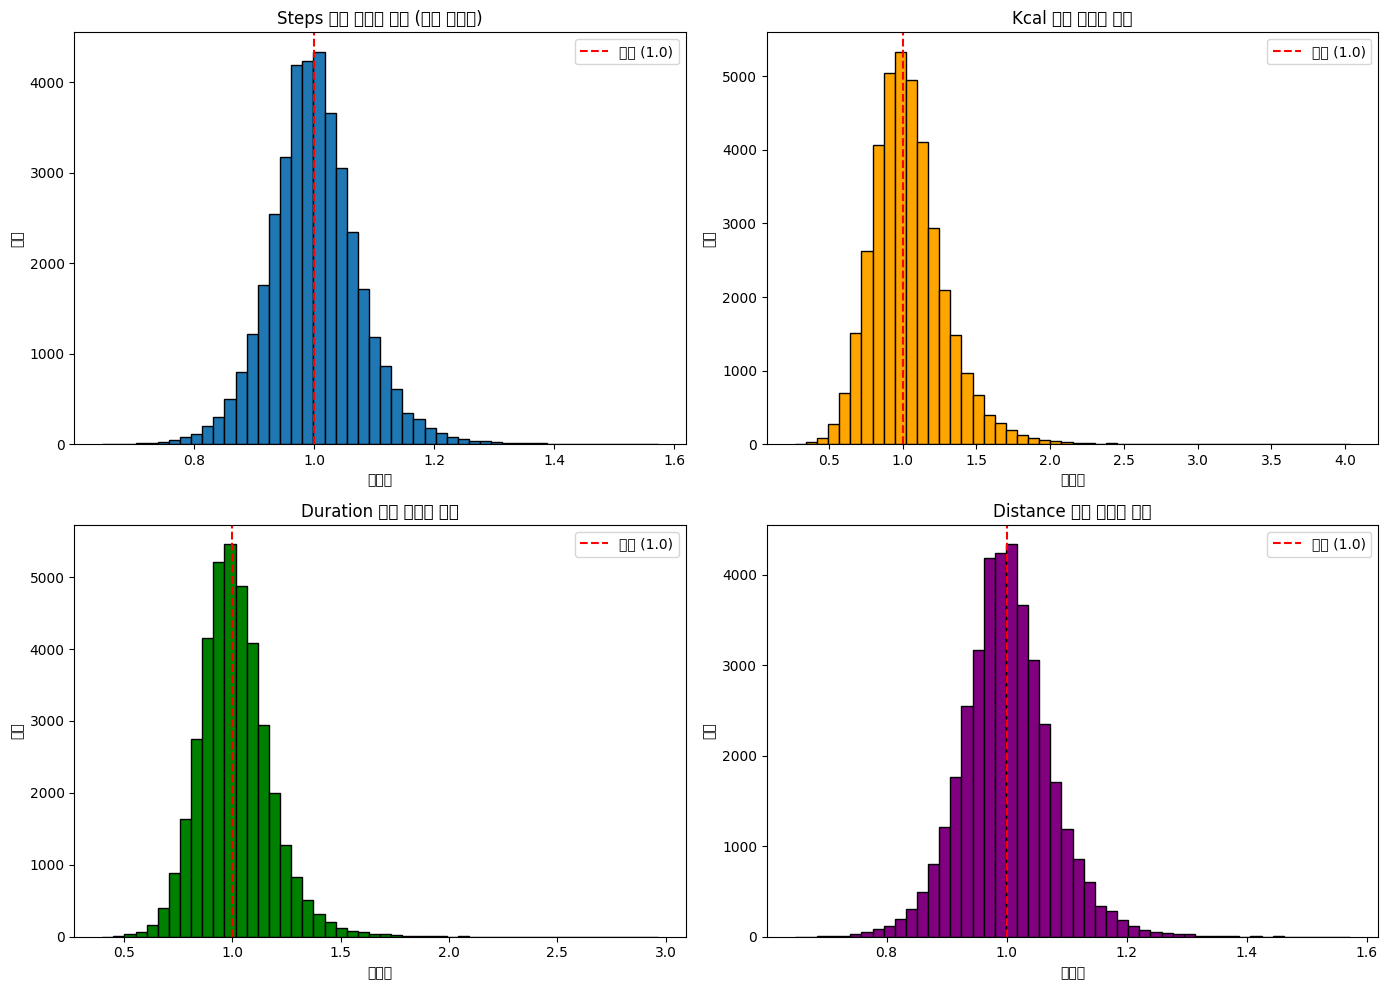


💡 이 분포를 모델이 학습합니다!
   공식이 아닌 실제 사람들의 개선 패턴입니다.


In [13]:
# 12. 개선률 분포 시각화 (실제 데이터 패턴 확인)

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Steps 개선률
axes[0, 0].hist(weekly_group_stats['improvement_rate_steps'], bins=50, edgecolor='black')
axes[0, 0].axvline(1.0, color='red', linestyle='--', label='유지 (1.0)')
axes[0, 0].set_title('Steps 주간 개선률 분포 (실제 데이터)')
axes[0, 0].set_xlabel('개선률')
axes[0, 0].set_ylabel('빈도')
axes[0, 0].legend()

# Kcal 개선률
axes[0, 1].hist(weekly_group_stats['improvement_rate_kcal'], bins=50, edgecolor='black', color='orange')
axes[0, 1].axvline(1.0, color='red', linestyle='--', label='유지 (1.0)')
axes[0, 1].set_title('Kcal 주간 개선률 분포')
axes[0, 1].set_xlabel('개선률')
axes[0, 1].set_ylabel('빈도')
axes[0, 1].legend()

# Duration 개선률
axes[1, 0].hist(weekly_group_stats['improvement_rate_duration'], bins=50, edgecolor='black', color='green')
axes[1, 0].axvline(1.0, color='red', linestyle='--', label='유지 (1.0)')
axes[1, 0].set_title('Duration 주간 개선률 분포')
axes[1, 0].set_xlabel('개선률')
axes[1, 0].set_ylabel('빈도')
axes[1, 0].legend()

# Distance 개선률
axes[1, 1].hist(weekly_group_stats['improvement_rate_distance'], bins=50, edgecolor='black', color='purple')
axes[1, 1].axvline(1.0, color='red', linestyle='--', label='유지 (1.0)')
axes[1, 1].set_title('Distance 주간 개선률 분포')
axes[1, 1].set_xlabel('개선률')
axes[1, 1].set_ylabel('빈도')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

print("\n💡 이 분포를 모델이 학습합니다!")
print("   공식이 아닌 실제 사람들의 개선 패턴입니다.")

In [14]:
# 10. 학습 데이터 저장 (4개 CSV)

print("="*60)
print("💾 학습 데이터 저장 중...")
print("="*60)

# Steps
steps_cols = [
    'member_count', 'group_avg_steps_14', 'last_week_achievement_rate',
    'avg_age', 'avg_bmi', 'avg_resting_hr', 'season',
    'group_weekly_active_rate', 'user_min_steps', 'next_goal_steps'
]
training_steps = weekly_group_stats[steps_cols].dropna()
training_steps.to_csv('../data/processed/training_steps.csv', index=False)
print(f"✅ training_steps.csv: {len(training_steps)} rows")

# Kcal
kcal_cols = [
    'member_count', 'group_avg_kcal_14', 'last_week_achievement_rate',
    'avg_age', 'avg_bmi', 'avg_resting_hr', 'season',
    'group_weekly_active_rate', 'user_min_kcal', 'next_goal_kcal'
]
training_kcal = weekly_group_stats[kcal_cols].dropna()
training_kcal.to_csv('../data/processed/training_kcal.csv', index=False)
print(f"✅ training_kcal.csv: {len(training_kcal)} rows")

# Duration
duration_cols = [
    'member_count', 'group_avg_duration_14', 'last_week_achievement_rate',
    'avg_age', 'avg_bmi', 'avg_resting_hr', 'season',
    'group_weekly_active_rate', 'user_min_duration', 'next_goal_duration'
]
training_duration = weekly_group_stats[duration_cols].dropna()
training_duration.to_csv('../data/processed/training_duration.csv', index=False)
print(f"✅ training_duration.csv: {len(training_duration)} rows")

# Distance
distance_cols = [
    'member_count', 'group_avg_distance_14', 'last_week_achievement_rate',
    'avg_age', 'avg_bmi', 'avg_resting_hr', 'season',
    'group_weekly_active_rate', 'user_min_distance', 'next_goal_distance'
]
training_distance = weekly_group_stats[distance_cols].dropna()
training_distance.to_csv('../data/processed/training_distance.csv', index=False)
print(f"✅ training_distance.csv: {len(training_distance)} rows")

print("\n✨ 전처리 완료! 이제 모델이 실제 개선 패턴을 학습합니다.")

💾 학습 데이터 저장 중...
✅ training_steps.csv: 38199 rows
✅ training_kcal.csv: 38199 rows
✅ training_duration.csv: 38199 rows
✅ training_distance.csv: 38199 rows

✨ 전처리 완료! 이제 모델이 실제 개선 패턴을 학습합니다.
